In [24]:
import osmnx as ox

import pandas as pd
import geopandas as gpd
import shapely
import pyrosm

pd.set_option("display.max_columns", None)

In [25]:
fp = "chile-latest.osm.pbf"
place_name = "Concepción, Chile"

place_string = "_".join(place_name.lower().split(",")[0].split(" "))

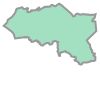

In [26]:
area_gdf = ox.geocode_to_gdf(place_name)
area = area_gdf.geometry.iloc[0]
area

In [7]:
# load the file with all osm data and clip with boundary
osm = pyrosm.OSM(fp, bounding_box=area)

# download the buildings
buildings = osm.get_buildings()
buildings

,addr:city,addr:country,addr:housenumber,addr:housename,addr:postcode,addr:place,addr:street,email,name,opening_hours,operator,phone,visible,website,building,amenity,building:flats,building:levels,craft,height,internet_access,landuse,office,shop,source,start_date,wikipedia,id,timestamp,version,tags,osm_type,geometry,changeset
0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,Casino Federación de Estudiantes,NaN,NaN,NaN,True,NaN,yes,restaurant,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,83103963,1559266433,6,NaN,way,"POLYGON ((-73.01369 -36.82376, -73.01358 -36.8...",NaN
1,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,Vicerrectoría de Asuntos Económicos,NaN,NaN,NaN,True,NaN,yes,NaN,NaN,2,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,83106230,1560553232,5,NaN,way,"POLYGON ((-73.01423 -36.82134, -73.01417 -36.8...",NaN
2,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,Facultad de Ciencias,NaN,NaN,NaN,True,NaN,university,NaN,NaN,3,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,83106231,1566618374,8,NaN,way,"POLYGON ((-73.01361 -36.82164, -73.0134 -36.82...",NaN
3,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,True,NaN,yes,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,83106241,1515187883,2,NaN,way,"POLYGON ((-73.01269 -36.82394, -73.01258 -36.8...",NaN
4,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,Departamento de Ingeniería Mecánica,NaN,NaN,NaN,True,NaN,university,NaN,NaN,2,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,83106253,1559412120,4,NaN,way,"POLYGON ((-73.01233 -36.82163, -73.01206 -36.8...",NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
5900,Concepción,NaN,NaN,NaN,4030000,NaN,Cochrane,NaN,NaN,NaN,NaN,NaN,True,NaN,church,NaN,NaN,3,NaN,8.4,NaN,NaN,NaN,NaN,NaN,NaN,NaN,10320075,1621317955,3,"{""type"":""multipolygon"",""members"":[{""member_id""...",relation,"POLYGON ((-73.04366 -36.82729, -73.0438 -36.82...",0.0
5901,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,True,NaN,hospital,NaN,NaN,4,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,10462735,1626627751,3,"{""type"":""multipolygon"",""members"":[{""member_id""...",relation,"POLYGON ((-73.0309 -36.81324, -73.03122 -36.81...",0.0
5902,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,Dirección de Desarrollo Estudiantil,NaN,NaN,NaN,True,NaN,yes,NaN,NaN,1,NaN,NaN,NaN,NaN,yes,NaN,NaN,NaN,NaN,10591613,1607895392,2,"{""type"":""multipolygon"",""members"":[{""member_id""...",relation,"POLYGON ((-73.01355 -36.82325, -73.01369 -36.8...",0.0
5903,Concepción,NaN,NaN,NaN,NaN,NaN,Avenida Jorge Alessandri,NaN,Escuela de Formación de Carabineros de Concepción,NaN,NaN,NaN,True,NaN,college,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,18623340,1738101264,1,"{""type"":""multipolygon"",""members"":[{""member_id""...",relation,"POLYGON ((-73.06695 -36.79976, -73.06707 -36.7...",0.0


In [ ]:
# load the file with all osm data and clip with boundary
osm = pyrosm.OSM(fp, bounding_box=area)

# download the features
pois = osm.get_pois(custom_filter=tags)

pois = pois.to_crs(32718)
pois.geometry = pois.geometry.centroid
pois = pois.to_crs(4326)

pois = pois[~pois["amenity"].isna()]
pois = pois[pois['amenity'] != 'bench']

pois.lon = pois.geometry.x
pois.lat = pois.geometry.y
pois = pois.rename(columns={"lon": "x", "lat": "y"})

pois = pois[["id", "x", "y", "amenity", "geometry"]]

In [9]:
buildings.building.value_counts().to_dict()

{'yes': 3211,
 'house': 1639,
 'apartments': 383,
 'detached': 167,
 'terrace': 119,
 'residential': 66,
 'university': 61,
 'school': 55,
 'roof': 49,
 'commercial': 42,
 'church': 16,
 'office': 14,
 'hospital': 14,
 'industrial': 12,
 'retail': 9,
 'supermarket': 6,
 'semidetached_house': 5,
 'public': 4,
 'garage': 4,
 'chapel': 4,
 'warehouse': 3,
 'college': 3,
 'train_station': 2,
 'temple': 2,
 'parking': 2,
 'oficinas': 1,
 'hotel': 1,
 'no': 1,
 'garages': 1,
 'synagogue': 1,
 'shed': 1,
 'guardhouse': 1,
 'civic': 1,
 'government': 1,
 'kindergarten': 1,
 'static_caravan': 1,
 'dormitory': 1,
 'stadium': 1}

In [10]:
edges_gdf = gpd.read_file(f"./network/{place_string}.gpkg", layer="edges", encoding="latin-1")

(-36.8623217, -36.7747554)

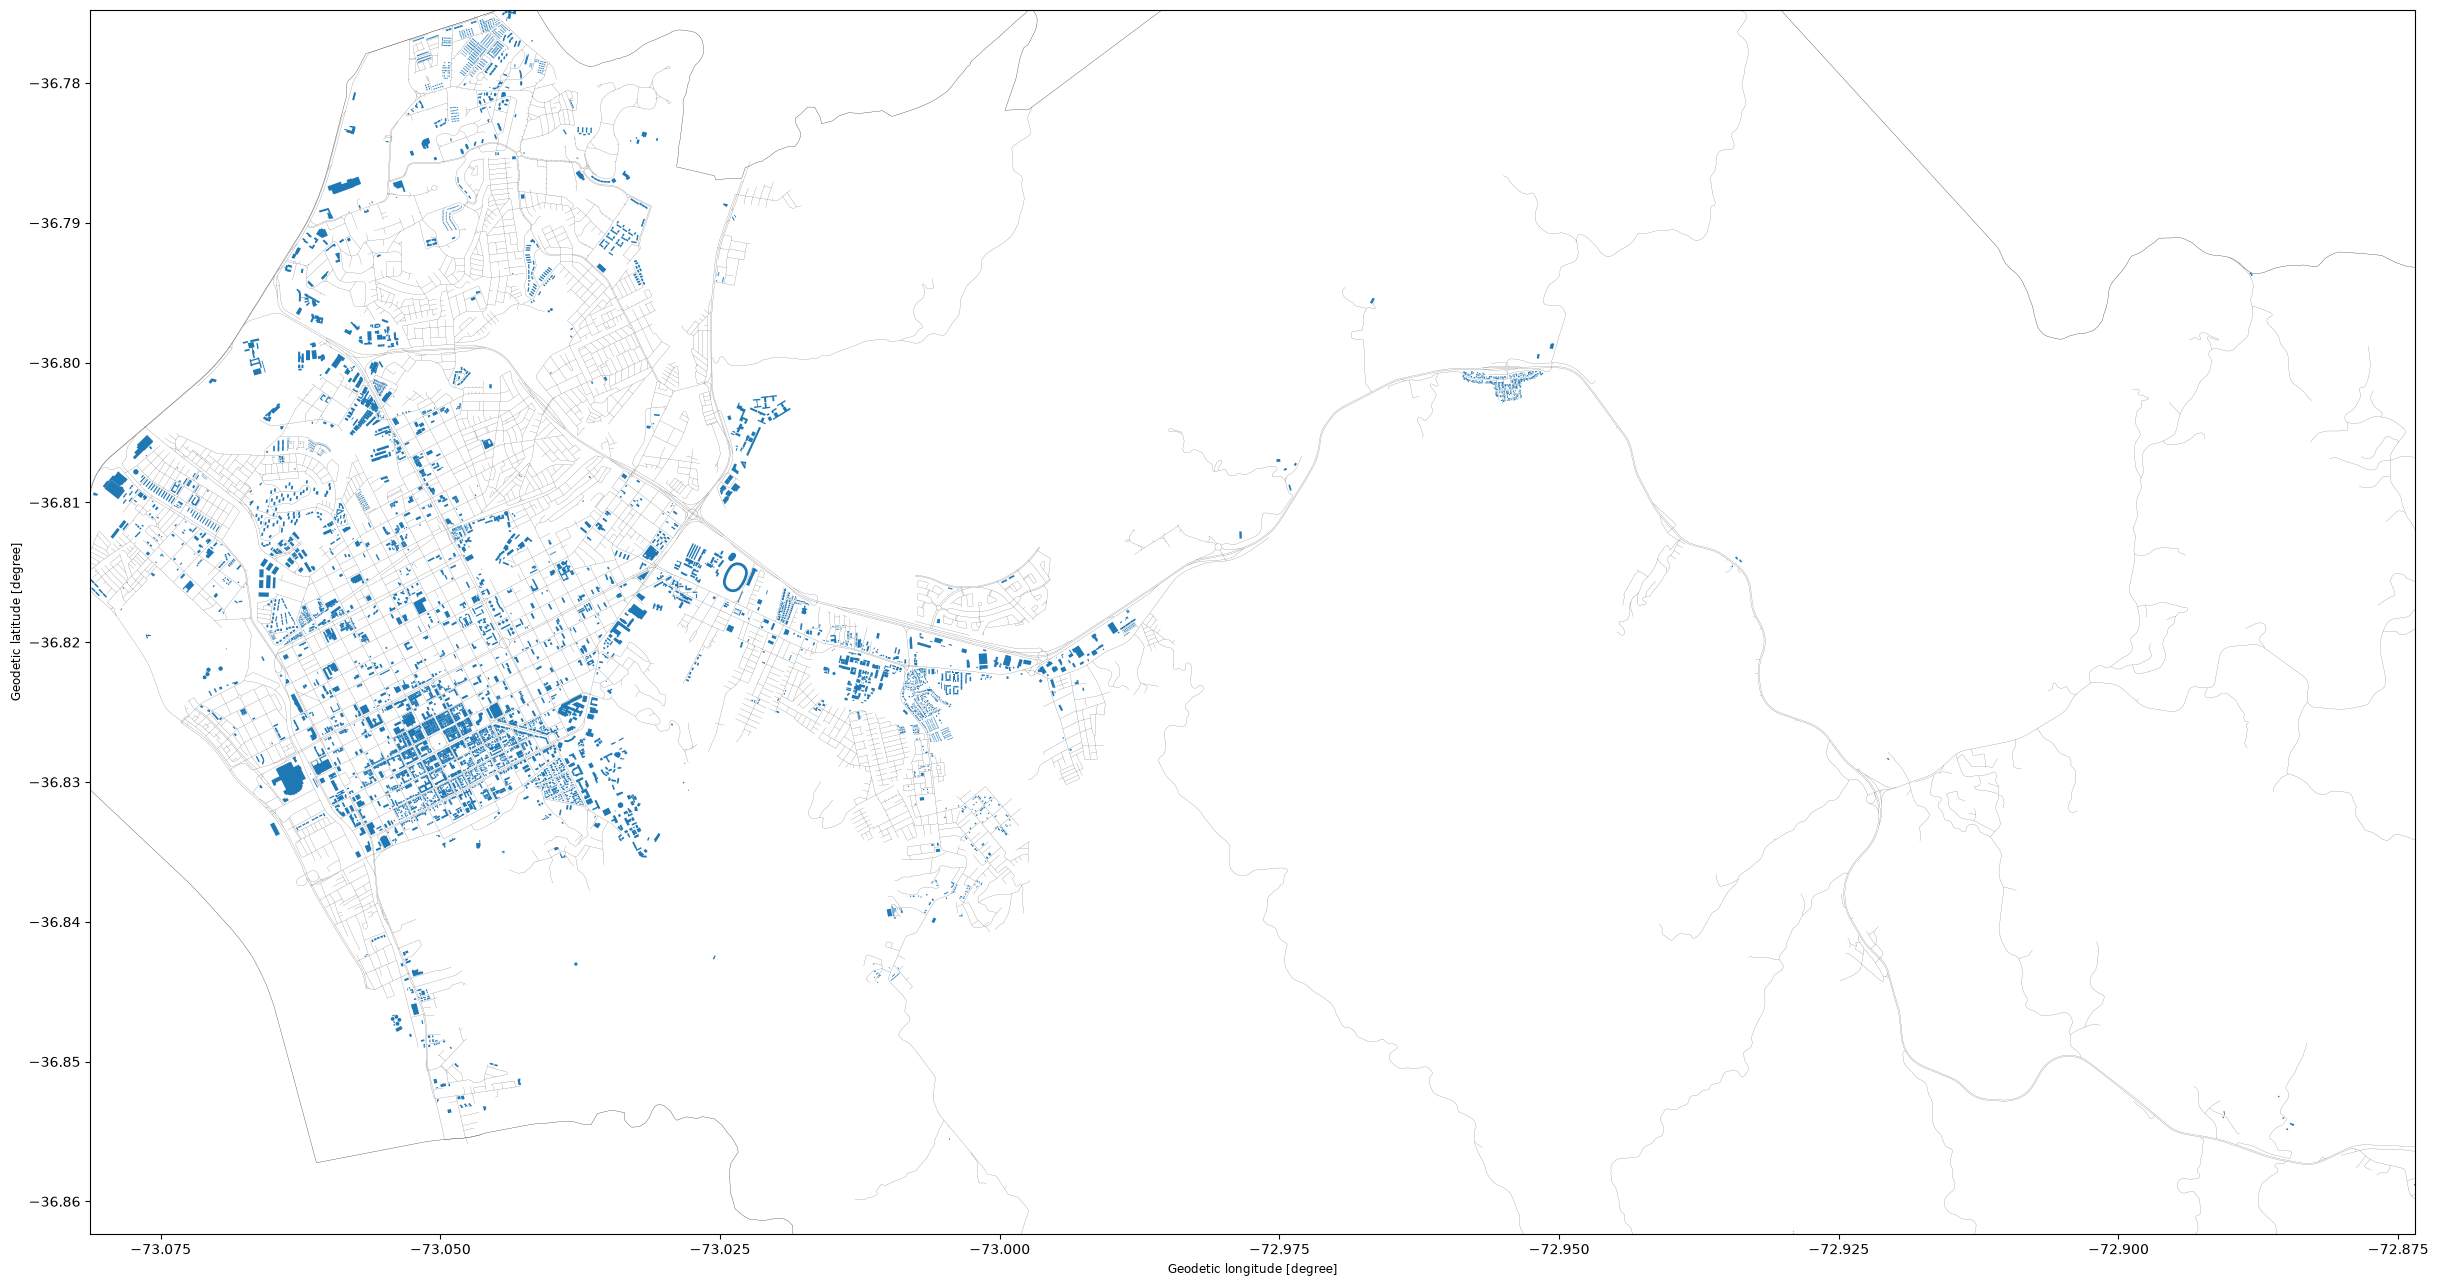

In [13]:
ax = buildings.plot(figsize=(30,30))
edges_gdf.plot(ax=ax, color="black", linewidth=0.1)
area_gdf.plot(ax=ax, color="none", linewidth=0.2)

ax.set_xlim(buildings.total_bounds[0], buildings.total_bounds[2])
ax.set_ylim(buildings.total_bounds[1], buildings.total_bounds[3])

In [ ]:
buildings.to_parquet(f"buildings/buildings_{place_string}.parquet")

In [ ]:
filename = "967_buildings.csv"

with open(filename, "r", encoding="utf-8") as f:
  lines = f.readlines()

if not lines[-1].strip().endswith('"'):
  print("Truncated line detected. Removing it...")
  lines.pop()

fixed_filename = "967_buildings_fixed.csv"
with open(fixed_filename, "w", encoding="utf-8") as f:
  f.writelines(lines)

In [18]:
blocks_gdf = gpd.read_parquet("blocks/Cartografia_censo2024_Pais_Manzanas.parquet")
blocks_gdf = blocks_gdf[blocks_gdf.COMUNA == "CONCEPCIÓN"]
# blocks_gdf = blocks_gdf[blocks_gdf.PROVINCIA == "CONCEPCIÓN"]
blocks_gdf = blocks_gdf[blocks_gdf.n_per > 0]
blocks_gdf

,OBJECTID,CUT,COD_REGION,REGION,COD_PROVINCIA,PROVINCIA,COMUNA,AREA_C,MANZENT,DISTRITO,COD_DISTRITO,COD_LOCALIDAD,COD_ZONA,LOCALIDAD,COD_ENTIDAD,COD_MANZANA,ENTIDAD,TIPO_MZ,COD_CATEGORIA,CATEGORIA,MZ_BASE_CENSO,ID_ENTIDAD,ID_LOCALIDAD,ID_DISTRITO,ID_ZONA,n_per,n_hombres,n_mujeres,n_edad_0_5,n_edad_6_13,n_edad_14_17,n_edad_18_24,n_edad_25_44,n_edad_45_59,n_edad_60_mas,prom_edad,n_inmigrantes,n_nacionalidad,n_pueblos_orig,n_afrodescendencia,n_lengua_indigena,n_religion,n_dificultad_ver,n_dificultad_oir,n_dificultad_mover,n_dificultad_cogni,n_dificultad_cuidado,n_dificultad_comunic,n_discapacidad,n_estcivcon_casado,n_estcivcon_conviviente,n_estcivcon_conv_civil,n_estcivcon_anul_sep_div,n_estcivcon_viudo,n_estcivcon_soltero,prom_escolaridad18,n_asistencia_parv,n_asistencia_basica,n_asistencia_media,n_asistencia_superior,n_cine_nunca_curso_primera_infancia,n_cine_primaria,n_cine_secundaria,n_cine_terciaria_maestria_doctorado,n_cine_especial_diferencial,n_analfabet,n_ocupado,n_desocupado,n_fuera_fuerza_trabajo,n_cise_rec_independientes,n_cise_rec_dependientes,n_cise_rec_trabajador_no_remunerado,n_ciuo_1,n_ciuo_2,n_ciuo_3,n_ciuo_4,n_ciuo_5,n_ciuo_6,n_ciuo_7,n_ciuo_8,n_ciuo_9,n_ciuo_0,n_caenes_A,n_caenes_B,n_caenes_C,n_caenes_D,n_caenes_E,n_caenes_F,n_caenes_G,n_caenes_H,n_caenes_I,n_caenes_J,n_caenes_K,n_caenes_L,n_caenes_M,n_caenes_N,n_caenes_O,n_caenes_P,n_caenes_Q,n_caenes_R,n_caenes_S,n_caenes_T,n_caenes_U,n_transporte_auto,n_transporte_publico,n_transporte_camina,n_transporte_bicicleta,n_transporte_motocicleta,n_transporte_cab_lan_bote,n_transporte_otros,n_hog,prom_per_hog,n_hog_unipersonales,n_hog_60,n_hog_menores,n_jefatura_mujer,n_tenencia_propia_pagada,n_tenencia_propia_pagandose,n_tenencia_arrendada_contrato,n_tenencia_arrendada_sin_contrato,n_tenencia_cedida_trabajo,n_tenencia_cedida_familiar,n_tenencia_otro,n_comb_cocina_gas,n_comb_cocina_parafina,n_comb_cocina_lena,n_comb_cocina_pellet,n_comb_cocina_carbon,n_comb_cocina_electricidad,n_comb_cocina_solar,n_comb_cocina_no_utiliza,n_comb_calefaccion_gas,n_comb_calefaccion_parafina,n_comb_calefaccion_lena,n_comb_calefaccion_pellet,n_comb_calefaccion_carbon,n_comb_calefaccion_electricidad,n_comb_calefaccion_otra,n_comb_calefaccion_no_utiliza,n_serv_tel_movil,n_serv_compu,n_serv_tablet,n_serv_internet_fija,n_serv_internet_movil,n_serv_internet_satelital,n_internet,n_vp,n_vp_ocupada,n_vp_desocupada,n_tipo_viv_casa,n_tipo_viv_depto,n_tipo_viv_indigena,n_tipo_viv_pieza,n_tipo_viv_mediagua,n_tipo_viv_movil,n_tipo_viv_otro,n_dormitorios_1,n_dormitorios_2,n_dormitorios_3,n_dormitorios_4,n_dormitorios_5,n_dormitorios_6_o_mas,n_viv_hacinadas,n_viv_irrecuperables,n_hog_allegados,n_nucleos_hacinados_allegados,n_viv_no_ampliables,n_deficit_cuantitativo,n_mat_paredes_hormigon,n_mat_paredes_albanileria,n_mat_paredes_tabique_forrado,n_mat_paredes_tabique_sin_forro,n_mat_paredes_artesanal,n_mat_paredes_precarios,n_mat_techo_tejas,n_mat_techo_hormigon,n_mat_techo_zinc,n_mat_techo_fibrocemento,n_mat_techo_fonolita,n_mat_techo_paja,n_mat_techo_precarios,n_mat_techo_sin_cubierta,n_mat_piso_radier_con_revestimiento,n_mat_piso_radier_sin_revestimiento,n_mat_piso_baldosa_cemento,n_mat_piso_capa_cemento,n_mat_piso_tierra,n_fuente_agua_publica,n_fuente_agua_pozo,n_fuente_agua_camion,n_fuente_agua_rio,n_distrib_agua_llave,n_distrib_agua_llave_fuera,n_distrib_agua_acarreo,n_serv_hig_alc_dentro,n_serv_hig_alc_fuera,n_serv_hig_fosa,n_serv_hig_pozo,n_serv_hig_acequia_canal,n_serv_hig_cajon_otro,n_serv_hig_bano_quimico,n_serv_hig_bano_seco,n_serv_hig_no_tiene,n_fuente_elect_publica,n_fuente_elect_diesel,n_fuente_elect_solar,n_fuente_elect_eolica,n_fuente_elect_otro,n_fuente_elect_no_tiene,n_basura_servicios,n_basura_entierra,n_basura_eriazo,n_basura_rio,n_basura_otro,SHAPE_Length,SHAPE_Area,SHAPE
19454,19455,8101,8,BIOBÍO,81,CONCEPCIÓN,CONCEPCIÓN,URBANO,8.101011e+12,INTENDENCIA,1,7,1,GRAN CONCEPCIÓN,1,1,CONCEPCIÓN,URBANO,1,Ciudad,1,8.101007e+11,81011007.0,810101.0,810101001.0,19.0,15.0,4.0,1.0,0.0,0.0,1.0,6

In [ ]:
buildings_df = pd.read_csv("967_buildings.csv", engine="c", usecols=["geometry"])

In [29]:
building_geoms = buildings_df.geometry.apply(shapely.wkt.loads)
building_geoms

0          POLYGON ((-73.0371866084166 -36.7948252568355,...
1          POLYGON ((-68.8484604097925 -32.9676691232373,...
2          POLYGON ((-72.0966811967563 -36.9779444377915,...
3          POLYGON ((-72.1260603300031 -36.6159446703355,...
4          POLYGON ((-73.1504011342381 -37.095087180879, ...
                                 ...                        
4751263    POLYGON ((-67.5088810945208 -34.9972150023535,...
4751264    POLYGON ((-70.5331663571558 -33.4673291865445,...
4751265    POLYGON ((-72.1062918676554 -36.5933307139739,...
4751266    POLYGON ((-70.6243589258278 -33.4555406805409,...
4751267    POLYGON ((-69.1749061427031 -33.7010553943277,...
Name: geometry, Length: 4751268, dtype: object

In [ ]:
buildings_df = pd.read_csv("967_buildings.csv", engine="c", usecols=["confidence"])
buildings_df

,confidence
0,0.8334
1,0.6516
2,0.7186
3,0.8680
4,0.8197
...,...
4751263,0.7423
4751264,0.6717
4751265,0.6690
4751266,0.8266


In [31]:
buildings_gdf = gpd.GeoDataFrame(buildings_df, geometry=building_geoms)
buildings_gdf

,confidence,geometry
0,0.8334,"POLYGON ((-73.03719 -36.79483, -73.03722 -36.7..."
1,0.6516,"POLYGON ((-68.84846 -32.96767, -68.84854 -32.9..."
2,0.7186,"POLYGON ((-72.09668 -36.97794, -72.09673 -36.9..."
3,0.8680,"POLYGON ((-72.12606 -36.61594, -72.12616 -36.6..."
4,0.8197,"POLYGON ((-73.1504 -37.09509, -73.15047 -37.09..."
...,...,...
4751263,0.7423,"POLYGON ((-67.50888 -34.99722, -67.50893 -34.9..."
4751264,0.6717,"POLYGON ((-70.53317 -33.46733, -70.53327 -33.4..."
4751265,0.6690,"POLYGON ((-72.10629 -36.59333, -72.10627 -36.5..."
4751266,0.8266,"POLYGON ((-70.62436 -33.45554, -70.62436 -33.4..."


In [ ]:
# intersect with the city blocks with actual people living there (n_per > 0)
# match_indices = buildings_gdf.sindex.query(area, predicate="intersects")
match_indices = buildings_gdf.sindex.query(blocks_gdf.geometry, predicate="intersects")
buildings_gdf = buildings_gdf.iloc[match_indices[1]]
# buildings_gdf = buildings_gdf.reset_index()

<Axes: xlabel='x', ylabel='y'>

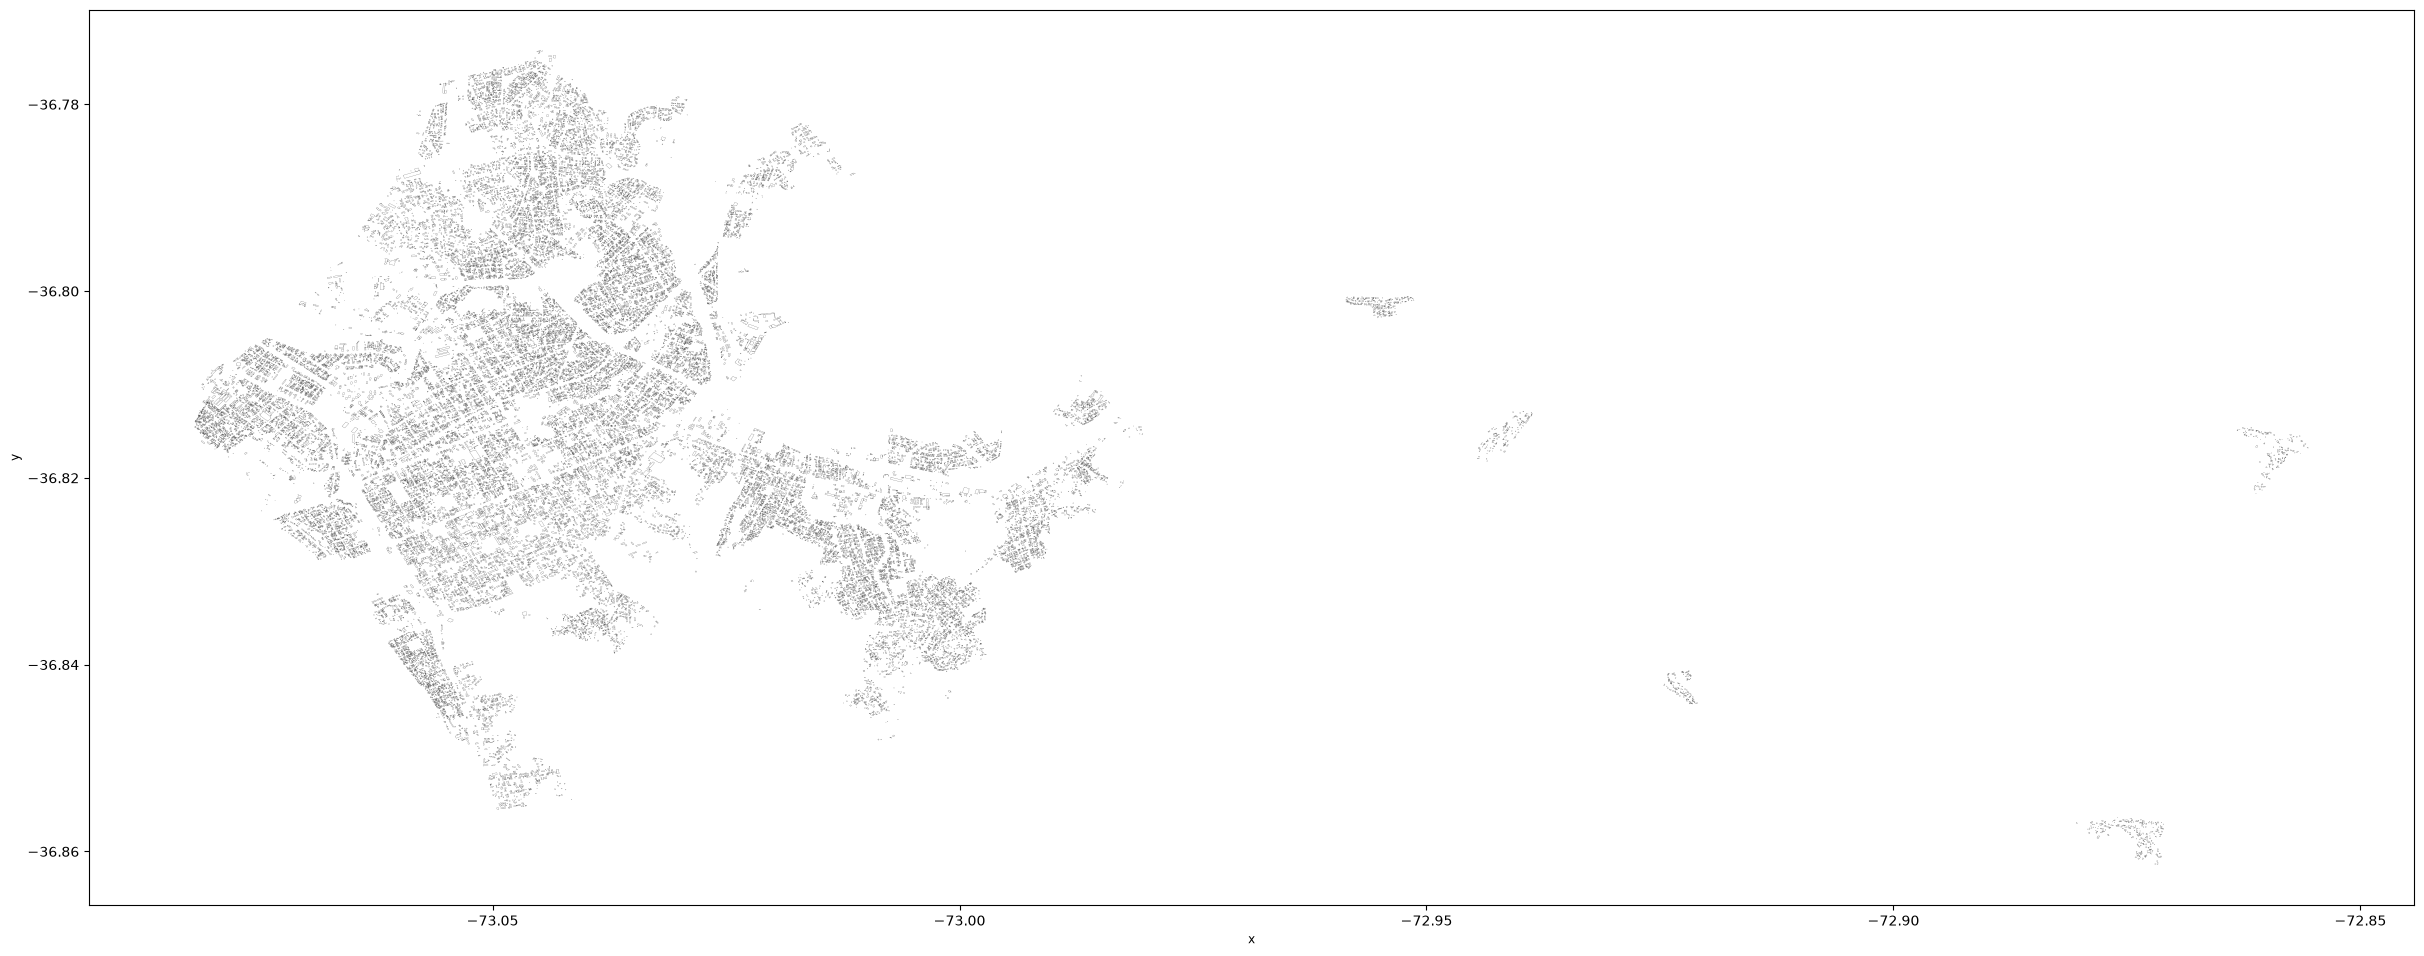

In [33]:
buildings_gdf.plot(figsize=(30,30), color="none", linewidth=0.1)

In [38]:
buildings_gdf.to_parquet(f"buildings/buildings_{place_string}.parquet")